Yuliia Chernysheva  
November 22, 2026  
CSC 2267: Maple Syrup Case Study

# Project Overview and Data Attribution

This case study investigates maple syrup production across the top ten U.S. producing states (Connecticut, Maine, Massachusetts, Michigan, New Hampshire, New York, Ohio, Pennsylvania, Vermont, and Wisconsin) for the census years 2012 and 2017. Aligned with **UN Sustainable Development Goal 15 (Life on Land)**, this analysis tests whether expanding maple sugaring operations increases syrup output, thereby creating a sustainable economic incentive to preserve mature sugarbush forests against timber harvesting and urban sprawl.

**Data Source Attribution:**  
All data are obtained from the U.S. Department of Agriculture (USDA), National Agricultural Statistics Service (NASS) Quick Stats database (https://quickstats.nass.usda.gov/). Per USDA Digital Rights and Copyrights policies (https://www.usda.gov/policies-and-links), public domain data are used with the requested attribution: *U.S. Department of Agriculture*.

# Obtain and Inspect the Data

In [1]:
# Import required libraries for data analysis,
# visualizations, and linear regression
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [2]:
# Load the four CSV files downloaded from USDA NASS Quick Stats
maplesyrup_farms = pd.read_csv("MapleSyrup_Farms.csv")
maplesyrup_days = pd.read_csv("MapleSyrup_Days.csv")
maplesyrup_taps = pd.read_csv("MapleSyrup_Taps.csv")
maplesyrup_gallons = pd.read_csv("MapleSyrup_Gallons.csv")

# Preview the first two rows of each raw dataset
display(maplesyrup_farms.head(2))
display(maplesyrup_days.head(2))
display(maplesyrup_taps.head(2))
display(maplesyrup_gallons.head(2))

,Program,Year,Period,Week Ending,Geo Level,State,State ANSI,Ag District,Ag District Code,County,...,Zip Code,Region,watershed_code,Watershed,Commodity,Data Item,Domain,Domain Category,Value,CV (%)
0,CENSUS,2017,YEAR,NaN,STATE,ARKANSAS,5,NaN,NaN,NaN,...,NaN,NaN,0,NaN,MAPLE SYRUP,MAPLE SYRUP - OPERATIONS WITH PRODUCTION,TOTAL,NOT SPECIFIED,3,69.6
1,CENSUS,2017,YEAR,NaN,STATE,CONNECTICUT,9,NaN,NaN,NaN,...,NaN,NaN,0,NaN,MAPLE SYRUP,MAPLE SYRUP - OPERATIONS WITH PRODUCTION,TAPS,TAPS: (1 TO 99 TAPS),88,85.1


,Program,Year,Period,Week Ending,Geo Level,State,State ANSI,Ag District,Ag District Code,County,...,Zip Code,Region,watershed_code,Watershed,Commodity,Data Item,Domain,Domain Category,Value,CV (%)
0,SURVEY,2017,YEAR,NaN,STATE,CONNECTICUT,9,NaN,NaN,NaN,...,NaN,NaN,0,NaN,MAPLE SYRUP,"MAPLE SYRUP - LENGTH OF SEASON, AVG, MEASURED ...",TOTAL,NOT SPECIFIED,42,NaN
1,SURVEY,2017,YEAR,NaN,STATE,INDIANA,18,NaN,NaN,NaN,...,NaN,NaN,0,NaN,MAPLE SYRUP,"MAPLE SYRUP - LENGTH OF SEASON, AVG, MEASURED ...",TOTAL,NOT SPECIFIED,31,NaN


,Program,Year,Period,Week Ending,Geo Level,State,State ANSI,Ag District,Ag District Code,County,...,Zip Code,Region,watershed_code,Watershed,Commodity,Data Item,Domain,Domain Category,Value,CV (%)
0,CENSUS,2017,YEAR,NaN,STATE,ARKANSAS,5,NaN,NaN,NaN,...,NaN,NaN,0,NaN,MAPLE SYRUP,MAPLE SYRUP - NUMBER OF TAPS,TOTAL,NOT SPECIFIED,70,30.1
1,CENSUS,2017,YEAR,NaN,STATE,CONNECTICUT,9,NaN,NaN,NaN,...,NaN,NaN,0,NaN,MAPLE SYRUP,MAPLE SYRUP - NUMBER OF TAPS,TAPS,TAPS: (1 TO 99 TAPS),"2,594",(H)


,Program,Year,Period,Week Ending,Geo Level,State,State ANSI,Ag District,Ag District Code,County,...,Zip Code,Region,watershed_code,Watershed,Commodity,Data Item,Domain,Domain Category,Value,CV (%)
0,CENSUS,2017,YEAR,NaN,STATE,ARKANSAS,5,NaN,NaN,NaN,...,NaN,NaN,0,NaN,MAPLE SYRUP,"MAPLE SYRUP - PRODUCTION, MEASURED IN GALLONS",TOTAL,NOT SPECIFIED,(D),(D)
1,CENSUS,2017,YEAR,NaN,STATE,CONNECTICUT,9,NaN,NaN,NaN,...,NaN,NaN,0,NaN,MAPLE SYRUP,"MAPLE SYRUP - PRODUCTION, MEASURED IN GALLONS",TAPS,TAPS: (1 TO 99 TAPS),496,(H)


# Clean the Data

## Initial Data Examination

Before filtering, we inspect column names, row counts, and data types across all four datasets.

In [3]:
# Inspect structure, non-null counts, and data types of each DataFrame
print("=> MAPLE SYRUP - OPERATIONS WITH PRODUCTION")
display(maplesyrup_farms.info())
print("\n=> MAPLE SYRUP - LENGTH OF SEASON, AVG, MEASURED IN DAYS")
display(maplesyrup_days.info())
print("\n=> MAPLE SYRUP - NUMBER OF TAPS")
display(maplesyrup_taps.info())
print("\n=> MAPLE SYRUP - PRODUCTION, MEASURED IN GALLONS")
display(maplesyrup_gallons.info())

=> MAPLE SYRUP - OPERATIONS WITH PRODUCTION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 239 entries, 0 to 238
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Program           239 non-null    object 
 1   Year              239 non-null    int64  
 2   Period            239 non-null    object 
 3   Week Ending       0 non-null      float64
 4   Geo Level         239 non-null    object 
 5   State             239 non-null    object 
 6   State ANSI        239 non-null    int64  
 7   Ag District       0 non-null      float64
 8   Ag District Code  0 non-null      float64
 9   County            0 non-null      float64
 10  County ANSI       0 non-null      float64
 11  Zip Code          0 non-null      float64
 12  Region            0 non-null      float64
 13  watershed_code    239 non-null    int64  
 14  Watershed         0 non-null      float64
 15  Commodity         239 non-null    object 
 16  

None


=> MAPLE SYRUP - LENGTH OF SEASON, AVG, MEASURED IN DAYS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Program           23 non-null     object 
 1   Year              23 non-null     int64  
 2   Period            23 non-null     object 
 3   Week Ending       0 non-null      float64
 4   Geo Level         23 non-null     object 
 5   State             23 non-null     object 
 6   State ANSI        23 non-null     int64  
 7   Ag District       0 non-null      float64
 8   Ag District Code  0 non-null      float64
 9   County            0 non-null      float64
 10  County ANSI       0 non-null      float64
 11  Zip Code          0 non-null      float64
 12  Region            0 non-null      float64
 13  watershed_code    23 non-null     int64  
 14  Watershed         0 non-null      float64
 15  Commodity         23 non-null     o

None


=> MAPLE SYRUP - NUMBER OF TAPS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 239 entries, 0 to 238
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Program           239 non-null    object 
 1   Year              239 non-null    int64  
 2   Period            239 non-null    object 
 3   Week Ending       0 non-null      float64
 4   Geo Level         239 non-null    object 
 5   State             239 non-null    object 
 6   State ANSI        239 non-null    int64  
 7   Ag District       0 non-null      float64
 8   Ag District Code  0 non-null      float64
 9   County            0 non-null      float64
 10  County ANSI       0 non-null      float64
 11  Zip Code          0 non-null      float64
 12  Region            0 non-null      float64
 13  watershed_code    239 non-null    int64  
 14  Watershed         0 non-null      float64
 15  Commodity         239 non-null    object 
 16  Data Item  

None


=> MAPLE SYRUP - PRODUCTION, MEASURED IN GALLONS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 239 entries, 0 to 238
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Program           239 non-null    object 
 1   Year              239 non-null    int64  
 2   Period            239 non-null    object 
 3   Week Ending       0 non-null      float64
 4   Geo Level         239 non-null    object 
 5   State             239 non-null    object 
 6   State ANSI        239 non-null    int64  
 7   Ag District       0 non-null      float64
 8   Ag District Code  0 non-null      float64
 9   County            0 non-null      float64
 10  County ANSI       0 non-null      float64
 11  Zip Code          0 non-null      float64
 12  Region            0 non-null      float64
 13  watershed_code    239 non-null    int64  
 14  Watershed         0 non-null      float64
 15  Commodity         239 non-null    object 

None

## Filter Target States, `TOTAL` Domain Rows, and Relevant Columns

Raw USDA NASS exports include state-level aggregate rows (`Domain == 'TOTAL'`) alongside size-bracket subcategories (`Domain == 'TAPS'`, such as `1 TO 99 TAPS` or `100 TO 499 TAPS`). Summing across all rows without filtering by `Domain` would double-count state totals. Therefore, we filter strictly for `Domain == 'TOTAL'`, select the ten target states, and retain only `Year`, `State`, and `Value`.

**Note on Suppressed `(D)` Values:**  

In USDA NASS datasets, `(D)` indicates data *withheld to avoid disclosing figures for individual operations*. Filtering for `Domain == 'TOTAL'` across the top ten producing states removes suppressed size-bracket entries, and coercing `Value` to numeric safely handles any remaining non-numeric symbols.

In [4]:
# Define target columns and the top 10 maple syrup producing states
target_column = ['Year','State','Value']
target_states = ['CONNECTICUT', 'MAINE', 'MASSACHUSETTS',
                 'MICHIGAN', 'NEW HAMPSHIRE', 'NEW YORK', 
                 'OHIO',  'PENNSYLVANIA', 'VERMONT', 'WISCONSIN']

# Filter for state-level totals (Domain == 'TOTAL') and target states to avoid double-counting

# Keep only necessary columns and rows
maplesyrup_farms = maplesyrup_farms.loc[
    (maplesyrup_farms['State'].isin(target_states)) & (maplesyrup_farms['Domain'] == 'TOTAL'),
    target_column
]
maplesyrup_days = maplesyrup_days.loc[
    (maplesyrup_days['State'].isin(target_states)) & (maplesyrup_days['Domain'] == 'TOTAL'),
    target_column
]
maplesyrup_taps = maplesyrup_taps.loc[
    (maplesyrup_taps['State'].isin(target_states)) & (maplesyrup_taps['Domain'] == 'TOTAL'),
    target_column
]
maplesyrup_gallons = maplesyrup_gallons.loc[
    (maplesyrup_gallons['State'].isin(target_states)) & (maplesyrup_gallons['Domain'] == 'TOTAL'),
    target_column
]

## Standardize Years (2013 Proxy for 2012 Season Length)

The USDA conducts comprehensive agricultural censuses every five years (2012 and 2017). However, average sap-harvesting season length (`Days`) comes from annual surveys that only begin in 2013. Following project guidelines, the 2013 `Days` records are reassigned to 2012 as a proxy so all four metrics align across both census years.

In [5]:
# Reassign Year 2013 to 2012 in the Days dataset to serve as a proxy for 2012
maplesyrup_days['Year'] = maplesyrup_days.Year.replace(2013,2012)

# Remove thousand-separator commas, convert Value to numeric (coercing '(D)' to NaN), and drop missing rows
maplesyrup_farms['Value'] = maplesyrup_farms.Value.astype(str).str.replace(',','',regex=False)
maplesyrup_farms['Value'] = pd.to_numeric(maplesyrup_farms['Value'], errors='coerce')
maplesyrup_farms = maplesyrup_farms.dropna()

maplesyrup_days['Value'] = maplesyrup_days.Value.astype(str).str.replace(',','',regex=False)
maplesyrup_days['Value'] = pd.to_numeric(maplesyrup_days['Value'], errors='coerce')
maplesyrup_days = maplesyrup_days.dropna()

maplesyrup_taps['Value'] = maplesyrup_taps.Value.astype(str).str.replace(',','',regex=False)
maplesyrup_taps['Value'] = pd.to_numeric(maplesyrup_taps['Value'], errors='coerce')
maplesyrup_taps = maplesyrup_taps.dropna()

maplesyrup_gallons['Value'] = maplesyrup_gallons.Value.astype(str).str.replace(',','',regex=False)
maplesyrup_gallons['Value'] = pd.to_numeric(maplesyrup_gallons['Value'], errors='coerce')
maplesyrup_gallons = maplesyrup_gallons.dropna()

# Rename the generic Value column to descriptive variable names
maplesyrup_farms = maplesyrup_farms.rename(columns={'Value':'Farms'})
maplesyrup_days = maplesyrup_days.rename(columns={'Value':'Days'})
maplesyrup_taps = maplesyrup_taps.rename(columns={'Value':'Taps'})
maplesyrup_gallons = maplesyrup_gallons.rename(columns={'Value':'Gallons'})

# Prepare the Data

## Merge into Wide Form and Reshape to Long Form

We merge the four cleaned datasets on `State` and `Year` to create a single wide-format table (10 states * 2 years * 4 metrics = 80 data points), and then melt it into long format for grouped plotting.

In [6]:
maplesyrup_farms = maplesyrup_farms.groupby(['State','Year'], as_index=False).sum(numeric_only=True)
maplesyrup_taps = maplesyrup_taps.groupby(['State','Year'], as_index=False).sum(numeric_only=True)
maplesyrup_gallons = maplesyrup_gallons.groupby(['State','Year'], as_index=False).sum(numeric_only=True)

# Merge all four metrics into a single wide-format DataFrame
maple_syrup = (
    maplesyrup_farms        
        .merge(maplesyrup_taps, on=['State','Year'], how='outer')
        .merge(maplesyrup_days, on=['State','Year'], how='outer')
        .merge(maplesyrup_gallons, on=['State','Year'], how='outer')
)

# Sort by Year (descending) and State (alphabetical) and display the final wide dataset
maple_syrup = maple_syrup.sort_values(['Year','State'], ascending=[False,True]).reset_index(drop=True)
display(maple_syrup)

,State,Year,Farms,Taps,Days,Gallons
0,CONNECTICUT,2017,199,78211,42,17378
1,MAINE,2017,557,1932219,41,717837
2,MASSACHUSETTS,2017,307,316447,42,75513
3,MICHIGAN,2017,875,664289,32,175519
4,NEW HAMPSHIRE,2017,528,594708,42,157267
5,NEW YORK,2017,1675,2749512,43,714372
6,OHIO,2017,820,465934,33,93672
7,PENNSYLVANIA,2017,637,835104,39,166021
8,VERMONT,2017,1411,5894508,46,2020159
9,WISCONSIN,2017,1399,987418,29,240035


## Create a New DataFrame in Long Form

In [7]:
# Reshape the wide dataset into long format using melt() 
maple_syrup_long = maple_syrup.melt(
    id_vars=['Year','State'],
    value_vars=['Farms','Taps','Days','Gallons'],
    var_name='Metric',
    value_name='Value'
)
display(maple_syrup_long.head())

,Year,State,Metric,Value
0,2017,CONNECTICUT,Farms,199
1,2017,MAINE,Farms,557
2,2017,MASSACHUSETTS,Farms,307
3,2017,MICHIGAN,Farms,875
4,2017,NEW HAMPSHIRE,Farms,528


# Analyze the Data

## Descriptive Statistics by Year

The summary table below presents the count, sum, average (mean), minimum, maximum, and standard deviation for `Taps`, `Days`, `Farms`, and `Gallons` in 2012 and 2017.

In [8]:
# Compute descriptive statistics per year for each variable
desc_stats = maple_syrup.groupby('Year')[['Taps', 'Days', 'Farms', 'Gallons']].agg(
    ['count', 'sum', 'mean', 'min', 'max', 'std']
).T
display(desc_stats)

Year                   2012          2017
Taps    count  1.000000e+01  1.000000e+01
        sum    1.114764e+07  1.451835e+07
        mean   1.114764e+06  1.451835e+06
        min    6.398500e+04  7.821100e+04
        max    4.348163e+06  5.894508e+06
        std    1.320753e+06  1.755973e+06
Days    count  1.000000e+01  1.000000e+01
        sum    3.720000e+02  3.890000e+02
        mean   3.720000e+01  3.890000e+01
        min    2.900000e+01  2.900000e+01
        max    4.100000e+01  4.600000e+01
        std    3.938415e+00  5.586691e+00
Farms   count  1.000000e+01  1.000000e+01
        sum    7.577000e+03  8.408000e+03
        mean   7.577000e+02  8.408000e+02
        min    1.660000e+02  1.990000e+02
        max    1.553000e+03  1.675000e+03
        std    4.745581e+02  5.001086e+02
Gallons count  1.000000e+01  1.000000e+01
        sum    2.261692e+06  4.377773e+06
        mean   2.261692e+05  4.377773e+05
        min    1.049500e+04  1.737800e+04
        max    9.993910e+05  2.020159e+06
        std    3.069718e+05  6.097056e+05

## Data Visualizations

To examine production patterns across states and census years, we construct:

* **Pie Chart:** Each state's percentage share of total 2017 maple syrup production (`Gallons`).
* **Horizontal Bar Chart:** Total 10-state `Gallons` produced in 2012 versus 2017.
* **Vertical Bar Chart:** State-by-state comparison of `Gallons` produced in 2012 and 2017.
* **Scatter Plot & Pairplot:** Bivariate relationships between `Gallons` and the independent variables (`Taps`, `Farms`, and `Days`).

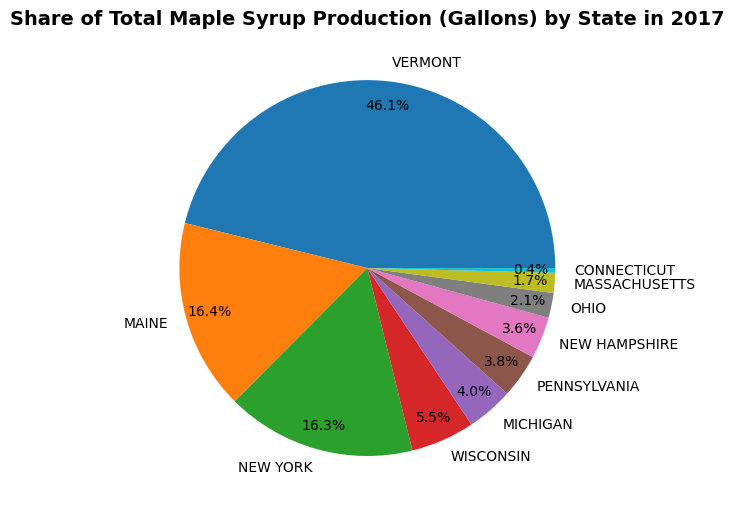

In [9]:
# Pie chart: Share of 2017 Maple Syrup Production (Gallons) by State
data_2017 = maple_syrup[maple_syrup['Year'] == 2017].sort_values('Gallons', ascending=False)

plt.figure(figsize=(6,6))
plt.pie(
    data_2017['Gallons'],
    labels=data_2017['State'],
    autopct='%1.1f%%',
    pctdistance=0.87
)    

plt.title('Share of Total Maple Syrup Production (Gallons) by State in 2017', 
          fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

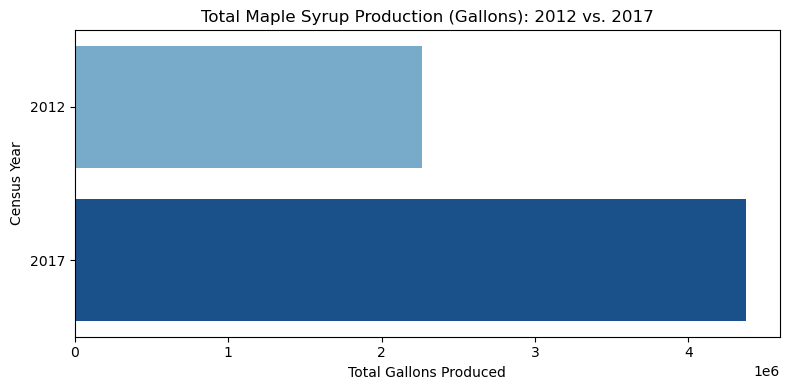

In [10]:
# Horizontal Bar Chart: Total Gallons Produced by Year
yearly_gallons = maple_syrup.groupby('Year', as_index=False)['Gallons'].sum()

plt.figure(figsize=(8,4))
sns.barplot(data=yearly_gallons, 
            x='Gallons',y='Year',
            hue='Year',
            orient='h',
            palette={2012: '#6BAED6', 2017: '#08519C'},
            legend=False
           )

plt.title('Total Maple Syrup Production (Gallons): 2012 vs. 2017')
plt.xlabel('Total Gallons Produced')
plt.ylabel('Census Year')
plt.tight_layout()
plt.show()

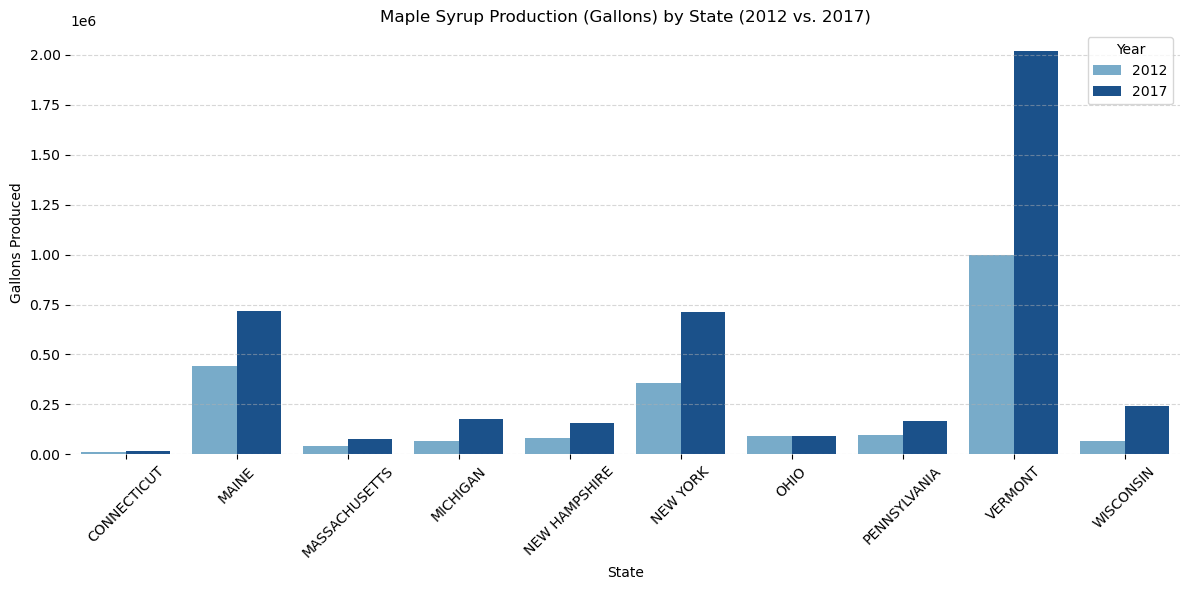

In [11]:
# Vertical Bar Chart: Maple Syrup Production (Gallons) by State and Year
plt.figure(figsize=(12, 6))
sns.barplot(data=maple_syrup, 
            x='State', 
            y='Gallons', 
            hue='Year', 
            palette={2012: '#6BAED6', 2017: '#08519C'})

plt.title('Maple Syrup Production (Gallons) by State (2012 vs. 2017)')
plt.xlabel('State')
plt.ylabel('Gallons Produced')
plt.xticks(rotation=45)
plt.box(False)
plt.grid(True, axis='y', which="major", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

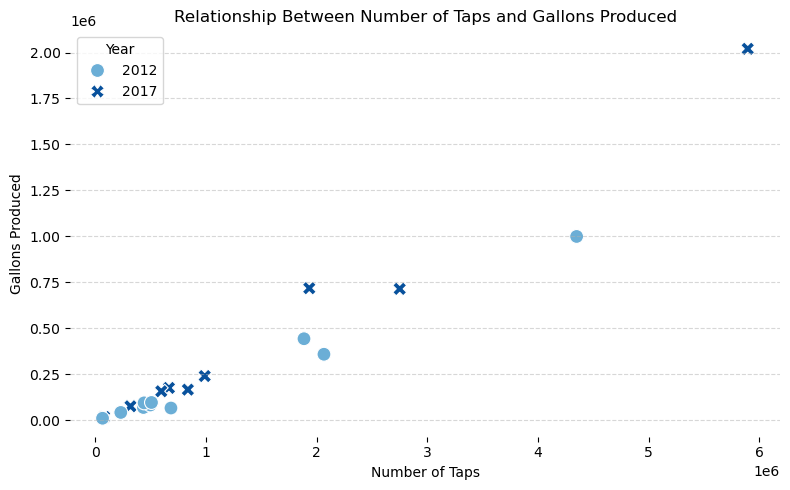

In [12]:
# Scatter Plot: Number of Taps vs. Gallons Produced
plt.figure(figsize=(8, 5))
sns.scatterplot(data=maple_syrup, 
                x='Taps', 
                y='Gallons', 
                hue='Year', 
                style='Year', 
                palette={2012: '#6BAED6', 2017: '#08519C'},
                s=100)

plt.title('Relationship Between Number of Taps and Gallons Produced')
plt.xlabel('Number of Taps')
plt.ylabel('Gallons Produced')

plt.box(False)
plt.grid(True, axis='y', which="major", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

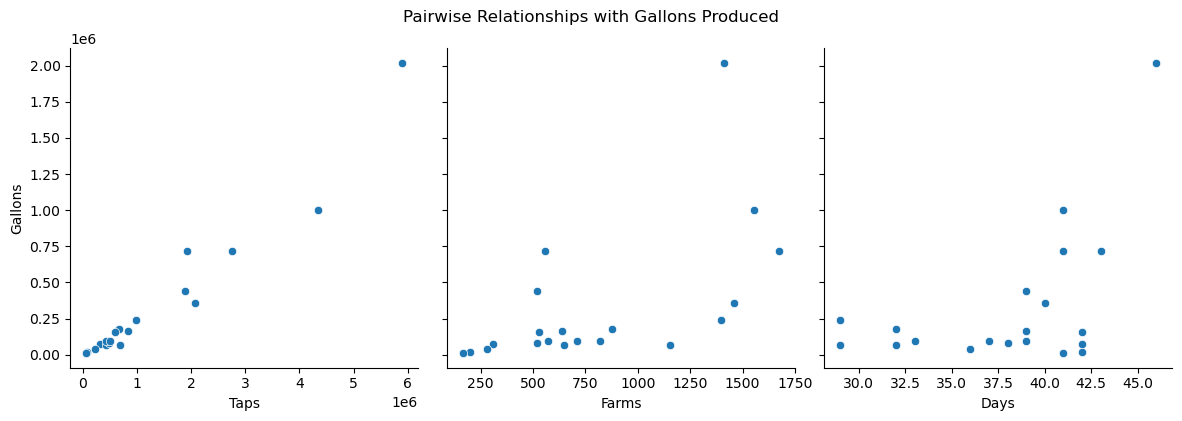

In [13]:
# Seaborn Pairplot: Side-by-side scatter plots of Gallons vs. Taps, Farms, and Days
sns.pairplot(
    data=maple_syrup,
    y_vars=['Gallons'],
    x_vars=['Taps', 'Farms', 'Days'],
    height=4
)
plt.suptitle('Pairwise Relationships with Gallons Produced', y=1.03)
plt.show()

## Pivot the Data: Gallons Produced by State and Year

In [14]:
# Pivot the dataset to display Gallons produced for each State across both Years
gallons_pivot = maple_syrup.pivot(index='Year', columns='State', values='Gallons')
display(gallons_pivot)

State,CONNECTICUT,MAINE,MASSACHUSETTS,MICHIGAN,NEW HAMPSHIRE,NEW YORK,OHIO,PENNSYLVANIA,VERMONT,WISCONSIN
Year,,,,,,,,,,
2012,10495,443024,42074,69017,82574,358603,94133,96266,999391,66115
2017,17378,717837,75513,175519,157267,714372,93672,166021,2020159,240035


## Correlation and R-Squared Analysis

In [15]:
# Calculate correlation coefficients with Gallons in descending order and compute R-squared
gallons_corr = maple_syrup[['Farms','Taps','Days','Gallons']]\
    .corr()[['Gallons']].sort_values(by='Gallons', ascending=False)

# Add R-squared 
corr_summary = gallons_corr.rename(columns={'Gallons':'Correlation (r)'})
corr_summary['R-squared'] = corr_summary['Correlation (r)'] ** 2

display(corr_summary)

,Correlation (r),R-squared
Gallons,1.000000,1.000000
Taps,0.970289,0.941460
Farms,0.578667,0.334856
Days,0.505043,0.255069


**Strength of the Relationships (Based on R-squared):**  

R-squared measures the proportion of variance in `Gallons` explained by each independent variable. `Taps` exhibits a very strong positive linear relationship with syrup production (R-squared > 0.94), confirming that higher tap counts directly drive higher output. By contrast, `Farms` and `Days` show noticeably lower R-squared values, meaning farm counts and season duration alone account for much less of the variation in total syrup produced.

**Usefulness for Forecasting Future Production:**  

While the high R-squared for `Taps` makes it reliable for estimating baseline production capacity when tap numbers are known, forecasts relying solely on these variables have three key limitations:
1. Projecting future `Gallons` requires first estimating future `Taps` and `Farms`.
2. The model omits weather factors (such as spring freeze-thaw cycles and temperature swings), which strongly impact annual sap flow.
3. Much of the strong correlation reflects differences in scale across states (such as Vermont compared to Connecticut) rather than year-to-year fluctuations within a single state.

## Correlation Heatmaps

First, we plot the full symmetric correlation matrix across all variables, followed by a consolidated heatmap showing only correlations with `Gallons` in descending order.

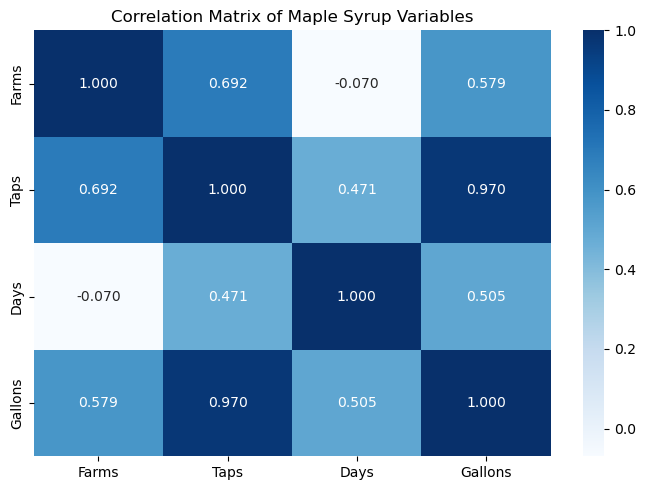

In [16]:
# Full symmetric heatmap showing every variable against every other variable
corr_matrix = maple_syrup[['Farms','Taps','Days','Gallons']].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    data=corr_matrix,
    annot=True,
    cmap='Blues',
    fmt='.3f'
)

plt.title('Correlation Matrix of Maple Syrup Variables')
plt.tight_layout()
plt.show()

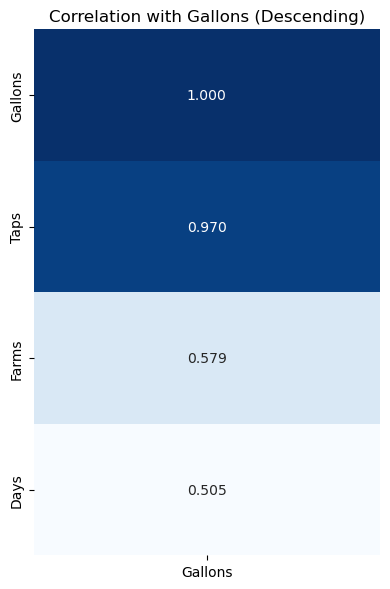

In [17]:
# Consolidated heatmap showing only Gallons as the dependent variable in descending order
plt.figure(figsize=(4, 6))
sns.heatmap(data=gallons_corr,
            annot=True,
            cmap='Blues',            
            cbar=False,
            fmt='.3f'
           )

plt.title('Correlation with Gallons (Descending)')
plt.tight_layout()
plt.show()

## Linear Regression Model (Scikit-Learn)

Using `scikit-learn`, we split the dataset into training (67%) and testing (33%) groups and train a linear regression model predicting `Gallons` from `Taps`.

In [18]:
# Split the data into training and testing subsets
x_train, x_test, y_train, y_test = train_test_split(
    maple_syrup[['Taps']],
    maple_syrup[['Gallons']],
    test_size=0.33, 
    random_state=42
)

# Train the linear regression model on the training set
linearModel = LinearRegression()
linearModel.fit(x_train, y_train)

# Evaluate the model R-squared score on the testing set
test_score = linearModel.score(x_test, y_test)
print(f"Test Set R-squared Score: {test_score:.4f}\n")

# Predict Gallons on the testing set and compare against actual values
y_predicted = linearModel.predict(x_test)
predictions_df = pd.DataFrame({
    'Test_Taps': x_test['Taps'].values,
    'Actual_Gallons': y_test['Gallons'].values,
    'Predicted_Gallons': y_predicted.flatten()
})
display(predictions_df)

Test Set R-squared Score: 0.8018



,Test_Taps,Actual_Gallons,Predicted_Gallons
0,78211,17378,3.927556e+03
1,506234,96266,1.035729e+05
2,2064864,358603,4.664277e+05
3,1932219,717837,4.355474e+05
4,5894508,2020159,1.357983e+06
5,2749512,714372,6.258162e+05
6,1884466,443024,4.244304e+05


# Summary and Environmental Advocacy Report

## Key Analytical Findings

An analysis of U.S. Department of Agriculture (USDA) National Agricultural Statistics Service (NASS) `TOTAL` state-level data across the top ten maple syrup producing states between 2012 and 2017 demonstrates substantial industry expansion:

* **Near-Doubling of Syrup Output:** Total maple syrup production across the ten states rose by `93.6%`, increasing from `2,261,692 gallons` in 2012 to `4,377,773 gallons` in 2017. Vermont remained the dominant producer in 2017 with `2,020,159 gallons` (`46.1%` of the ten-state total), followed by Maine (`717,837 gallons`, `16.4%`) and New York (`714,372 gallons`, `16.3%`).

* **Expansion of Taps and Farms:** Total installed taps increased by `30.2%`, growing from `11,147,637` in 2012 to `14,518,350` in 2017, while the number of maple farms with production rose by `11.0%`, from `7,577` to `8,408` operations.

* **Taps as the Primary Driver of Production:** Correlation and linear regression analyses confirm that the **number of taps** is by far the strongest predictor of maple syrup yield (`r = 0.970`, `R-squared = 0.941`), with the scikit-learn test set achieving an R-squared score of `0.8018`. Expanding tap infrastructure drives syrup volume far more reliably than merely increasing the count of small operations (`R-squared = 0.335`) or relying on season length (`R-squared = 0.255`).

## Implications for Forest Conservation (UN SDG 15)

These results directly support our main hypothesis. If we encourage more people to start maple syrup businesses and help current farmers add more taps, syrup production will grow. This makes keeping sugar maple forests alive much more profitable for landowners. Instead of cutting down mature trees for wood or new buildings, farmers will protect them. This directly supports **UN Sustainable Development Goal 15** by saving forest ecosystems (Target 15.1), helping trees store more carbon through sustainable forest management (Target 15.2), and protecting natural wildlife habitats (Target 15.5).

## Methodological Notes and Additional Variables

* **Filtering for State-Level Totals (`Domain == 'TOTAL'`):** Raw USDA NASS exports contain state-level aggregate rows (`Domain == 'TOTAL'`) alongside farm-size subcategories (`Domain == 'TAPS'`). Filtering strictly for `Domain == 'TOTAL'` prevents double-counting state figures and removes suppressed `(D)` subcategory entries.

* **Using 2013 `Days` Data Instead of 2012:** Because USDA NASS data for season length starts in 2013, we used the 2013 numbers to replace missing 2012 values. Even though spring weather changes every year, the average season length across the ten states stayed very similar (`37.2 days` in 2013 vs. `38.9 days` in 2017)and had only a weak link to syrup production (`R-squared = 0.255`). Because of this, using 2013 data lets us compare both census years without changing our main conclusion that taps drive syrup output.

* **Adding Weather Variables:** Future prediction models would be much more accurate if we added spring weather data. Sap flows best when daytime temperatures rise above freezing (`32° F`) after freezing nights, so tracking daily temperature changes, sunlight, and spring rain or snow would help explain yearly changes in syrup production.

## References

* U.S. Department of Agriculture, National Agricultural Statistics Service. *Quick Stats Database* (2012, 2013, and 2017 Maple Syrup Data). https://quickstats.nass.usda.gov/
  
* United Nations. *Goal 15: Life on Land*. Department of Economic and Social Affairs, Sustainable Development. https://sdgs.un.org/goals/goal15